# Completed notebook: execution guide
**Floyd Maloba | ST10544961 | ICE Task 3: Pipelines and Text Data**


# ICE Task 3: Pipelines and Text Data

## Objective

This project analyses Amazon Fine Food Reviews to identify
common areas of customer concern and praise, and classify
review sentiment as positive, neutral, or negative.

The analysis will use topic modelling and a sentiment
classification pipeline to generate actionable recommendations
for an online food retailer.

## Part 1: Model Selection and Dataset Justification

### 1.1 Model Selection

#### Identifying Themes: Latent Dirichlet Allocation (LDA)

LDA will be used with Bag of Words features to discover themes
in customer reviews. It identifies groups of words that commonly
occur together and represents each review as a mixture of topics.

This is appropriate because the reviews do not have predefined
theme labels.

**Strengths**
- Discovers themes without manually labelling every review.
- Produces topic keywords that can support business interpretation.
- Allows a review to contain more than one topic.

**Limitations**
- The number of topics must be selected.
- Topics may overlap or be difficult to interpret.
- Word counts do not fully capture word order or context.
- A topic alone does not indicate whether customers praise
  or criticise that subject.

**Expected outputs**
- Top keywords for each topic.
- Topic labels assigned after inspecting keywords and reviews.
- Representative reviews and topic prevalence.
- Topic comparisons across sentiment groups.

#### Sentiment Analysis: TF-IDF and Logistic Regression

A Scikit-Learn Pipeline will combine TF-IDF vectorisation
with Logistic Regression.

TF-IDF converts review text into numerical features that
reflect word importance. Logistic Regression then learns
to classify reviews into sentiment categories.

The rating-based labels will be:
- Negative: 1–2 stars.
- Neutral: 3 stars.
- Positive: 4–5 stars.

These ratings are proxies for sentiment and may not always
match the wording of a review.

**Strengths**
- Suitable for sparse text features.
- Less computationally demanding than many deep learning models.
- Provides an interpretable baseline.
- A Pipeline keeps feature extraction and classification together,
  allowing the vectoriser to be fitted only on training data.

**Limitations**
- May struggle with sarcasm and complex context.
- Rating-based labels can introduce label noise.
- Class imbalance may reduce performance on minority classes.

**Expected outputs**
- Predicted sentiment labels and class probabilities.
- Accuracy, precision, recall, F1-score, and a confusion matrix.
- A comparison between the baseline and a tuned model.

### 1.2 Dataset Justification

#### Relevance

Amazon Fine Food Reviews is relevant because it contains
customer feedback and ratings for food products sold on Amazon.
Review text supports theme discovery, while ratings provide
labels for sentiment classification.

#### Size and Diversity

The supplied CSV contains 568,454 records and 10 columns.
It includes product identifiers, reviewer information,
helpfulness counts, ratings, timestamps, review summaries,
and full review text.

The large dataset supports analysis across many reviews.
However, its historical coverage and product mix limit
how directly findings can be applied to a current retailer.

#### Data Quality

Initial inspection found:
- No missing values in `Text` or `Score`.
- No blank review texts.
- 26 missing profile names and 27 missing summaries.
- No duplicate complete rows.
- 174,875 repeated review texts beyond their first occurrence.

Repeated texts will be investigated before modelling.
The same cleaned review text must not appear in both
training and testing sets.

Text cleaning will address HTML, punctuation, casing, and
stopwords. Negation words such as "not" will be retained
because they affect sentiment.

Missing profile names do not prevent analysis because reviewer
names will not be used as model inputs.

#### Bias, Fairness, and Privacy

Positive reviews dominate the dataset. Performance will
therefore be assessed for each sentiment class, including
macro-F1, rather than relying only on overall accuracy.

People who leave reviews may differ from customers who do not.
Rating-based sentiment labels are also imperfect, and model
performance may vary across writing styles and product types.

Reviewer names and user identifiers will not be included in
the client report. Findings will describe this dataset and
will not be presented as representative of every Amazon customer.

#### Dataset Source

[Amazon Fine Food Reviews on Kaggle](https://www.kaggle.com/datasets/snap/amazon-fine-food-reviews)

## Part 2: Planning the Analysis

### 2.1 Exploratory Data Analysis Plan

The dataset will be inspected for missing values, duplicate
reviews, rating distribution, and review lengths.

| Step | Planned action |
|------|----------------|
| Missing values | Remove records with missing or blank review text or missing ratings. Missing profile names will not affect analysis because names are not model inputs. |
| Duplicates | Inspect repeated review texts and conflicting ratings. Remove conflicting text-label records and retain one record per normalised review text before splitting. |
| Lowercasing | Convert review text to lowercase so words such as "Food" and "food" are treated consistently. |
| Text cleaning | Remove HTML tags, decode HTML entities, remove punctuation while preserving word boundaries, and standardise whitespace. |
| Stopwords | Remove common words with little analytical value, while retaining negation words such as "not", "no", and "never". |
| Visualisations | Produce word-frequency plots, word clouds, review-length distributions, and sentiment-class counts. |

Cleaning counts will be recorded so that the effect of each
step can be explained. Reviews that become empty after
preprocessing will be removed.

### 2.2 Feature Selection Plan

| Technique | Purpose | Justification |
|-----------|---------|---------------|
| Bag of Words | Create word-count features for LDA topic modelling. | Word counts allow LDA to discover groups of words that commonly occur together. |
| TF-IDF | Create numerical features for sentiment classification. | Gives less weight to words occurring throughout the dataset and more weight to distinctive terms. |
| N-grams | Compare individual words with individual words plus two-word phrases. | Phrases such as "not good" can contain information that individual words miss. |

The baseline sentiment model will use unigram TF-IDF features.
The improvement stage will test unigrams and bigrams.

Vectorisers will be fitted only on training data during
sentiment modelling and within each cross-validation fold.

### 2.3 Model Training Plan

Sentiment labels will be derived from the ratings:
- Negative: 1–2 stars.
- Neutral: 3 stars.
- Positive: 4–5 stars.

Only review text will be used as the prediction input.
Ratings will create the target labels and will not be
included as features.

After cleaning, a reproducible stratified sample of up to
50,000 reviews will be used to keep computation manageable.
Class proportions will be preserved, and the sample size
and limitations will be documented.

The sample will be split into 80% training data and 20%
testing data using stratification and `random_state=42`.
This preserves approximately the same sentiment proportions
in both sets.

| Model or component | Initial parameters |
|--------------------|--------------------|
| TF-IDF | `max_features=10000`, `ngram_range=(1, 1)`, `min_df=2` |
| Logistic Regression | `C=1.0`, `max_iter=1000`, `class_weight=None` |
| Bag of Words for LDA | `max_features=5000`, `min_df=5`, `max_df=0.95` |
| LDA | `n_components=6`, `max_iter=10`, `learning_method="online"`, `random_state=42` |

A Pipeline will combine TF-IDF and Logistic Regression.
LDA will initially be fitted on training reviews, with topic
labels assigned after inspecting keywords and representative
reviews. Six topics is a starting choice, not an assumption
that six business themes must exist.

For model improvement, three-fold stratified cross-validation
on the training set will compare:
- Unigrams versus unigrams and bigrams.
- Logistic Regression `C` values of 0.5 and 2.0.
- No class weighting versus `class_weight="balanced"`.

The best configuration will be selected using macro-F1.
The test set will not be used to select parameters.

### 2.4 Evaluation Plan

| Evaluation method | Purpose |
|-------------------|---------|
| Accuracy | Measure the overall proportion of correct sentiment predictions. |
| Precision | Assess how often predictions for each sentiment class are correct. |
| Recall | Assess how many reviews belonging to each sentiment class are detected. |
| F1-score | Summarise precision and recall for each class. |
| Macro-F1 | Give each sentiment class equal importance despite class imbalance. |
| Confusion matrix | Show which sentiment categories are confused with one another. |

Baseline and tuned sentiment models will be evaluated
on the same untouched test set. Changes in performance
will be reported honestly, including any trade-offs.

LDA topics will be evaluated separately by inspecting
their keywords, representative reviews, distinctiveness,
and business usefulness. Sentiment classification metrics
will not be applied directly to unlabelled topics.

### 2.5 Reporting Plan

The final report will use plain language and contain:

| Required section | Planned content |
|------------------|-----------------|
| Introduction | Business problem and analysis objectives. |
| Dataset overview | Source, size, variables, scope, and ethical limitations. |
| Data cleaning and EDA | Cleaning decisions, records removed, class balance, word frequencies, word clouds, and review lengths. |
| Feature engineering | Simple explanations of Bag of Words, TF-IDF, and n-grams. |
| Model training | Selected models, Pipeline, split strategy, and parameters. |
| Model evaluation | Performance metrics, confusion matrix, weaknesses, and baseline-versus-improved comparison. |
| Key findings | Evidence-supported themes, commonly praised or criticised features, and sentiment patterns. |
| Recommendations | Practical actions linked to findings, with priorities and limitations. |

Themes will be compared across sentiment groups to distinguish
areas of praise from concern. Representative reviews will be
checked before assigning business labels to topics.

Any changes in sentiment over time will be examined using
review timestamps and review counts. Findings will describe
historical reviews rather than current customer satisfaction.
Reviewer names and identifiers will not appear in the report.

## Part 3: Conducting the Analysis

### 3.1 Exploratory Data Analysis

First, the required libraries are imported and the dataset
is loaded. We inspect its dimensions, columns, data types,
missing values, and rating distribution before cleaning.

The original dataset is preserved so that cleaning decisions
and changes in record counts can be tracked.

In [1]:
# Import libraries for data handling and text cleaning
import pandas as pd
import numpy as np
import re
import html

# Import libraries for visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Import tools for text features and modelling pipelines
from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer,
    ENGLISH_STOP_WORDS
)
from sklearn.pipeline import Pipeline
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.linear_model import LogisticRegression

# Import tools for splitting data, tuning, and evaluation
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

# Set a consistent visual style
sns.set_theme(style="whitegrid")

# Set a reproducible random seed
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Keep Reviews.csv next to this notebook, or set DATA_PATH to its location.
from pathlib import Path
DATA_PATH = Path('Reviews.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError('Place the original Reviews.csv beside this notebook, or update DATA_PATH.')
OUTPUT_DIR = Path('ice3_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()
print('Dataset shape:', df.shape)
# Do not display reviewer names or identifiers.
display(df[['Score', 'Summary', 'Text']].head())


Dataset shape: (568454, 10)


,Score,Summary,Text
0,5,Good Quality Dog Food,I have bought several of the Vitality canned dog food products and have found them all to be of good quality. The product looks more like a stew than a processed meat and it smells better. My Labrador is finicky and she appreciates this product better than most.
1,1,Not as Advertised,"Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted. Not sure if this was an error or if the vendor intended to represent the product as ""Jumbo""."
2,4,"""Delight"" says it all","This is a confection that has been around a few centuries. It is a light, pillowy citrus gelatin with nuts - in this case Filberts. And it is cut into tiny squares and then liberally coated with powdered sugar. And it is a tiny mouthful of heaven. Not too chewy, and very flavorful. I highly recommend this yummy treat. If you are familiar with the story of C.S. Lewis' ""The Lion, The Witch, and The Wardrobe"" - this is the treat that seduces Edmund into selling out his Brother and Sisters to the Witch."
3,2,Cough Medicine,If you are looking for the secret ingredient in Robitussin I believe I have found it. I got this in addition to the Root Beer Extract I ordered (which was good) and made some cherry soda. The flavor is very medicinal.
4,5,Great taffy,"Great taffy at a great price. There was a wide assortment of yummy taffy. Delivery was very quick. If your a taffy lover, this is a deal."


In [3]:
# Inspect column data types and non-null counts
df.info()
raw_missing = df.isna().sum().to_dict()
raw_duplicate_rows = int(df.duplicated().sum())
raw_duplicate_text = int(df['Text'].duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   Id                      568454 non-null  int64 
 1   ProductId               568454 non-null  object
 2   UserId                  568454 non-null  object
 3   ProfileName             568428 non-null  object
 4   HelpfulnessNumerator    568454 non-null  int64 
 5   HelpfulnessDenominator  568454 non-null  int64 
 6   Score                   568454 non-null  int64 
 7   Time                    568454 non-null  int64 
 8   Summary                 568427 non-null  object
 9   Text                    568454 non-null  object
dtypes: int64(5), object(5)
memory usage: 43.4+ MB


In [4]:
# Count missing values in each column
print("Missing values:")
print(df.isna().sum())

# Count completely duplicated rows
print("\nDuplicate complete rows:", df.duplicated().sum())

# Count repeated review texts beyond the first occurrence
print("Repeated review texts:", df["Text"].duplicated().sum())

# Count missing or whitespace-only review texts
blank_text = df["Text"].fillna("").str.strip().eq("")
print("Missing or blank review texts:", blank_text.sum())

# Inspect the number of reviews for each star rating
print("\nRating distribution:")
print(df["Score"].value_counts().sort_index())

Missing values:
Id                         0
ProductId                  0
UserId                     0
ProfileName               26
HelpfulnessNumerator       0
HelpfulnessDenominator     0
Score                      0
Time                       0
Summary                   27
Text                       0
dtype: int64

Duplicate complete rows: 0
Repeated review texts: 174875
Missing or blank review texts: 0

Rating distribution:
Score
1     52268
2     29769
3     42640
4     80655
5    363122
Name: count, dtype: int64


### Initial Dataset Findings

The dataset contains 568,454 reviews and 10 columns.
There are no missing or blank review texts and no missing ratings.

Missing values occur in 26 profile names and 27 summaries.
These do not prevent analysis because only full review text
will be used as the model input.

There are no duplicate complete rows, but 174,875 review texts
repeat beyond their first occurrence. Complete-row checks can
miss repeated reviews because identifiers may differ.

Five-star reviews dominate the dataset. Per-class metrics and
macro-F1 will therefore be important when evaluating sentiment.

### Text Cleaning and Duplicate Handling

Review text is lowercased, HTML is removed, HTML entities are
decoded, and punctuation is replaced with spaces.

Contractions are expanded before punctuation removal to
preserve negation. Stopwords are removed while retaining
"no", "not", "nor", and "never".

Sentiment labels are derived from ratings:
- 1–2 stars: negative.
- 3 stars: neutral.
- 4–5 stars: positive.

Reviews with identical normalised text but conflicting sentiment
labels are excluded. One record is retained for each remaining
normalised text. This reduces repeated content and prevents
identical model inputs appearing in training and testing sets.

This approach may also remove genuine repeated feedback,
which will be acknowledged as a limitation.

In [5]:
# Start from the original dataset so rerunning is reproducible
df = df_raw.copy()
starting_rows = len(df)

# Remove records without usable text or valid ratings
valid_rows = (
    df["Text"].notna()
    & df["Text"].fillna("").str.strip().ne("")
    & df["Score"].isin([1, 2, 3, 4, 5])
)
df = df.loc[valid_rows].copy()
invalid_removed = starting_rows - len(df)

# Create sentiment labels from ratings
sentiment_mapping = {
    1: "negative",
    2: "negative",
    3: "neutral",
    4: "positive",
    5: "positive"
}
df["sentiment"] = df["Score"].map(sentiment_mapping)

# Preserve negation words when removing stopwords
stop_words = set(ENGLISH_STOP_WORDS) - {"no", "not", "nor", "never"}

# Define a reusable text-cleaning function
def clean_review(text):
    # Decode HTML entities and standardise apostrophes
    text = html.unescape(str(text)).lower().replace("’", "'")

    # Remove HTML tags while preserving word boundaries
    text = re.sub(r"<[^>]+>", " ", text)

    # Expand common negative contractions before removing punctuation
    text = text.replace("won't", "will not")
    text = text.replace("can't", "can not")
    text = text.replace("shan't", "shall not")
    text = re.sub(r"n't\b", " not", text)

    # Replace punctuation and numbers with spaces
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove stopwords and standardise whitespace
    tokens = [
    word for word in text.split()
    if word not in stop_words and len(word) > 1
]
    return " ".join(tokens)

# Apply text normalisation
df["clean_text"] = df["Text"].apply(clean_review)

# Remove reviews that become empty after cleaning
empty_mask = df["clean_text"].eq("")
empty_removed = int(empty_mask.sum())
df = df.loc[~empty_mask].copy()

# Identify normalised texts linked to multiple sentiment labels
label_counts = df.groupby("clean_text")["sentiment"].nunique()
conflicting_texts = label_counts[label_counts > 1].index

# Remove all records belonging to conflicting text-label groups
conflict_mask = df["clean_text"].isin(conflicting_texts)
conflicting_removed = int(conflict_mask.sum())
df = df.loc[~conflict_mask].copy()

# Retain one record per remaining normalised review text
before_deduplication = len(df)
df = df.drop_duplicates(subset="clean_text").reset_index(drop=True)
duplicates_removed = before_deduplication - len(df)

# Report the effect of each cleaning step
print("Original records:", starting_rows)
print("Invalid text/rating records removed:", invalid_removed)
print("Empty cleaned reviews removed:", empty_removed)
print("Conflicting text-label records removed:", conflicting_removed)
print("Repeated cleaned reviews removed:", duplicates_removed)
print("Remaining records:", len(df))

# Check sentiment counts after cleaning
print("\nSentiment distribution after cleaning:")
print(df["sentiment"].value_counts())

# Preview original and cleaned text
display(df[["Text", "clean_text", "sentiment"]].head())
# Save the removal audit so the report uses measured counts.
cleaning_audit = pd.Series({
    'original': starting_rows, 'invalid_removed': invalid_removed,
    'empty_removed': empty_removed, 'conflicting_removed': conflicting_removed,
    'duplicates_removed': duplicates_removed, 'remaining': len(df)
})
assert starting_rows == invalid_removed + empty_removed + conflicting_removed + duplicates_removed + len(df)
cleaning_audit.to_csv(OUTPUT_DIR / 'cleaning_audit.csv')


Original records: 568454
Invalid text/rating records removed: 0
Empty cleaned reviews removed: 8
Conflicting text-label records removed: 215
Repeated cleaned reviews removed: 175363
Remaining records: 392868

Sentiment distribution after cleaning:
sentiment
positive    306261
negative     56925
neutral      29682
Name: count, dtype: int64


,Text,clean_text,sentiment
0,I have bought several of the Vitality canned dog food products and have found them all to be of good quality. The product looks more like a stew than a processed meat and it smells better. My Labrador is finicky and she appreciates this product better than most.,bought vitality canned dog food products good quality product looks like stew processed meat smells better labrador finicky appreciates product better,positive
1,"Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted. Not sure if this was an error or if the vendor intended to represent the product as ""Jumbo"".",product arrived labeled jumbo salted peanuts peanuts actually small sized unsalted not sure error vendor intended represent product jumbo,negative
2,"This is a confection that has been around a few centuries. It is a light, pillowy citrus gelatin with nuts - in this case Filberts. And it is cut into tiny squares and then liberally coated with powdered sugar. And it is a tiny mouthful of heaven. Not too chewy, and very flavorful. I highly recommend this yummy treat. If you are familiar with the story of C.S. Lewis' ""The Lion, The Witch, and The Wardrobe"" - this is the treat that seduces Edmund into selling out his Brother and Sisters to the Witch.",confection centuries light pillowy citrus gelatin nuts case filberts cut tiny squares liberally coated powdered sugar tiny mouthful heaven not chewy flavorful highly recommend yummy treat familiar story lewis lion witch wardrobe treat seduces edmund selling brother sisters witch,positive
3,If you are looking for the secret ingredient in Robitussin I believe I have found it. I got this in addition to the Root Beer Extract I ordered (which was good) and made some cherry soda. The flavor is very medicinal.,looking secret ingredient robitussin believe got addition root beer extract ordered good cherry soda flavor medicinal,negative
4,"Great taffy at a great price. There was a wide assortment of yummy taffy. Delivery was very quick. If your a taffy lover, this is a deal.",great taffy great price wide assortment yummy taffy delivery quick taffy lover deal,positive


### Verified cleaning outcomes
The current code retains **392,868** reviews from 568,454. It removes 0 invalid text/rating records, 8 empty cleaned texts, 215 records in conflicting text-sentiment groups and 175,363 further repeated cleaned texts.

Retained class counts are positive 306,261, negative 56,925 and neutral 29,682. These are unique normalised texts after exclusions, not counts of all customer submissions. The old written counts have been replaced with this execution's measured results.

### Sampling and Train-Test Split

A stratified random sample of 50,000 cleaned reviews is selected
to reduce computation while approximately preserving sentiment
class proportions.

The sample is split into 80% training and 20% testing data.
The test set is reserved for final model evaluation. Subsequent
exploratory plots and model development will use training data.

Sampling and splitting use `random_state=42` for reproducibility.
The sample does not guarantee representation of every product,
time period, or writing style.

In [6]:
# Select a stratified sample if the dataset exceeds 50,000 reviews
if len(df) > 50000:
    df_sample, _ = train_test_split(
        df,
        train_size=50000,
        stratify=df["sentiment"],
        random_state=RANDOM_STATE
    )
else:
    df_sample = df.copy()

# Split whole rows to preserve text, labels, and metadata together
train_df, test_df = train_test_split(
    df_sample,
    test_size=0.2,
    stratify=df_sample["sentiment"],
    random_state=RANDOM_STATE
)

# Create model inputs and target labels
X_train = train_df["clean_text"]
X_test = test_df["clean_text"]
y_train = train_df["sentiment"]
y_test = test_df["sentiment"]

# Confirm that identical cleaned texts do not cross the split
assert set(X_train).isdisjoint(set(X_test))

# Display sample and split sizes
print("Sample records:", len(df_sample))
print("Training records:", len(train_df))
print("Testing records:", len(test_df))

# Compare class proportions in the cleaned dataset and sample
proportions = pd.DataFrame({
    "Cleaned dataset (%)":
        df["sentiment"].value_counts(normalize=True) * 100,
    "Sample (%)":
        df_sample["sentiment"].value_counts(normalize=True) * 100
})

print("\nSentiment proportions:")
print(proportions.round(2))

Sample records: 50000
Training records: 40000
Testing records: 10000

Sentiment proportions:
           Cleaned dataset (%)  Sample (%)
sentiment                                 
positive                 77.96       77.95
negative                 14.49       14.49
neutral                   7.56        7.56


### Verified sampling results
A stratified sample contains 50,000 cleaned reviews and is split into 40,000 training and 10,000 test reviews. The exact proportions are printed above; small differences reflect integer rounding. Identical cleaned model inputs do not cross the split.

### Word-frequency plot
The following plot summarises the 20 most frequent words in cleaned training text. Frequency indicates discussion volume, not whether a term represents praise or criticism.

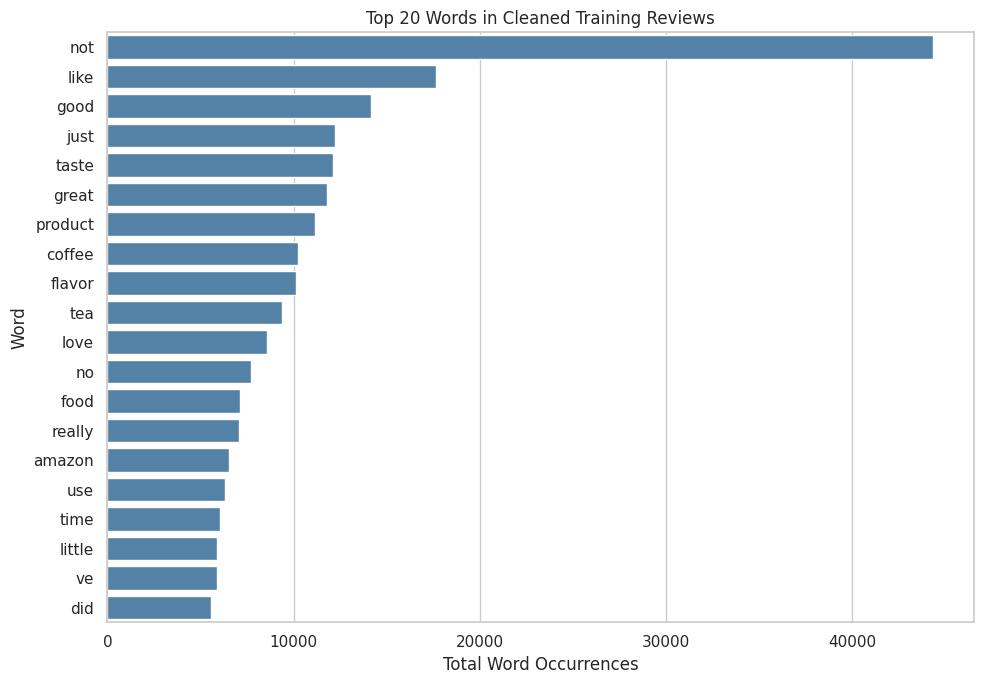

Word,Frequency
not,44327
like,17628
good,14159
just,12241
taste,12110
great,11790
product,11175
coffee,10230
flavor,10139
tea,9383


In [7]:

# Import a counter for counting individual word occurrences
from collections import Counter

# Count words across cleaned training reviews
word_counts = Counter()

for review in X_train:
    word_counts.update(review.split())

# Create a table containing the 20 most frequent words
top_words = pd.DataFrame(
    word_counts.most_common(20),
    columns=["Word", "Frequency"]
)

# Plot the most frequent words in descending order
plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_words,
    x="Frequency",
    y="Word",
    color="steelblue"
)

plt.title("Top 20 Words in Cleaned Training Reviews")
plt.xlabel("Total Word Occurrences")
plt.ylabel("Word")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "word_frequencies.png", dpi=180, bbox_inches="tight")
plt.show()

# Display exact counts alongside the visualisation
top_words
display(top_words)
top_words.to_csv(OUTPUT_DIR / "word_frequencies.csv", index=False)


### Review length, class balance and word clouds
Counts show retained training observations, not all original submissions. Review length is the number of whitespace-separated words in the original text; the histogram is displayed up to its 99th percentile for readability, without deleting longer records. Word clouds summarise word frequency within each rating-derived sentiment group. Common words alone do not establish a cause of satisfaction.

Cleaning uses a fixed stopword list and contraction rules; no lemmatisation is performed. Negation is retained, but removing intervening words may change the context represented by bigrams. These limitations are discussed rather than hidden.

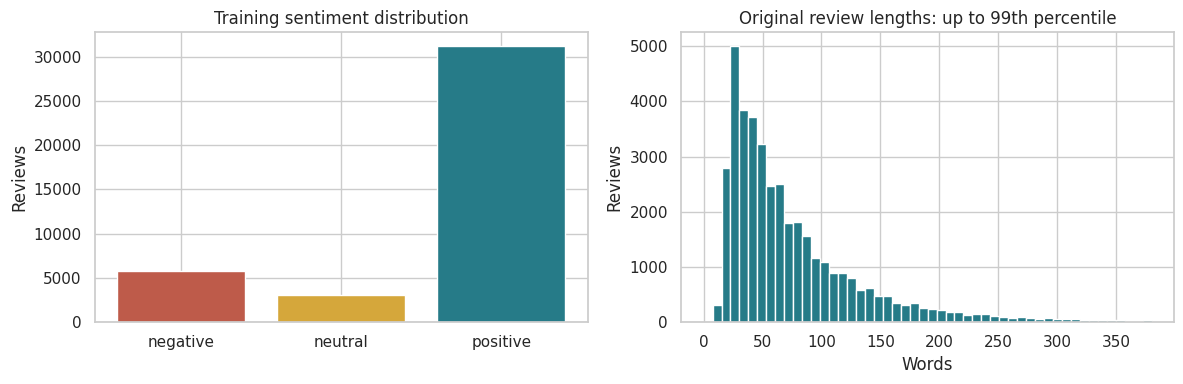

count    40000.00000
mean        79.77415
std         76.69395
min          4.00000
50%         57.00000
90%        159.00000
99%        380.00000
max       1458.00000
Name: Text, dtype: float64

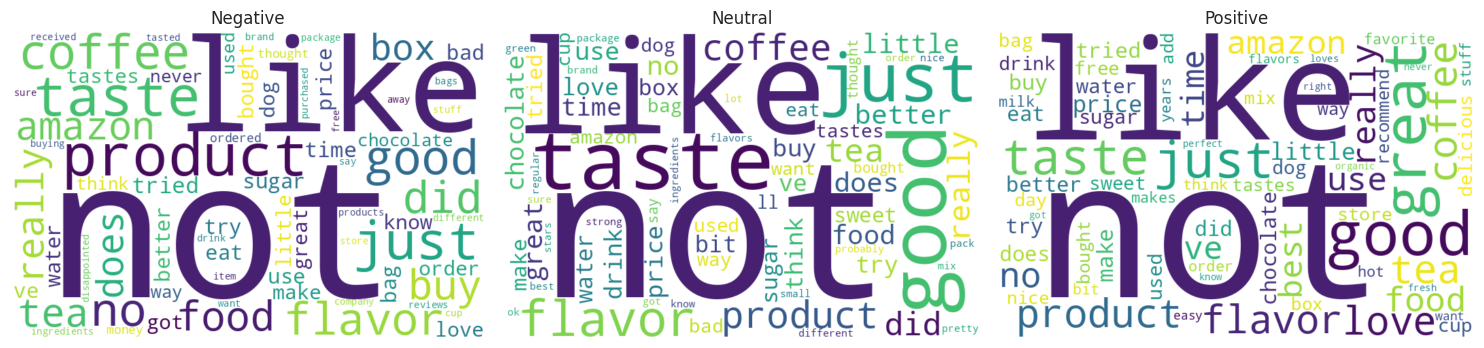

In [8]:
from collections import Counter
from wordcloud import WordCloud

CLASS_ORDER = ['negative', 'neutral', 'positive']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
class_counts = train_df['sentiment'].value_counts().reindex(CLASS_ORDER)
axes[0].bar(CLASS_ORDER, class_counts, color=['#BE5B4A', '#D5A73B', '#267B88'])
axes[0].set_title('Training sentiment distribution')
axes[0].set_ylabel('Reviews')

review_lengths = train_df['Text'].str.split().str.len()
length_limit = float(review_lengths.quantile(0.99))
axes[1].hist(review_lengths, bins=50, range=(0, length_limit), color='#267B88')
axes[1].set_title('Original review lengths: up to 99th percentile')
axes[1].set_xlabel('Words'); axes[1].set_ylabel('Reviews')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'class_balance_lengths.png', dpi=180)
plt.show()
length_summary = review_lengths.describe(percentiles=[0.5, 0.9, 0.99])
display(length_summary)
length_summary.to_csv(OUTPUT_DIR / 'review_lengths.csv')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, sentiment in zip(axes, CLASS_ORDER):
    frequencies = Counter()
    for text in train_df.loc[train_df['sentiment'] == sentiment, 'clean_text']:
        frequencies.update(text.split())
    cloud = WordCloud(width=700, height=450, background_color='white',
                      max_words=70, random_state=RANDOM_STATE, collocations=False)
    cloud.generate_from_frequencies(frequencies)
    ax.imshow(cloud, interpolation='bilinear')
    ax.set_title(sentiment.title()); ax.axis('off')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'sentiment_wordclouds.png', dpi=180)
plt.show()

### 3.2 TF-IDF features and baseline sentiment pipeline
The pipeline fits a vocabulary and inverse-document-frequency weights only on training text. It keeps at most 10,000 terms appearing in at least two training reviews. Unigrams form the baseline. The numerical matrix remains sparse to avoid a large dense allocation.

Logistic regression uses L2 regularisation, C=1.0 and up to 1,000 iterations. Three-class probabilities are learned from rating-derived labels; the star rating is never a predictor. Three-fold stratified training cross-validation provides baseline macro-F1 before improvement. A majority classifier supplies a simple reference. See scikit-learn developers (n.d.a; n.d.b).

In [9]:
from sklearn.model_selection import cross_val_score
from sklearn.dummy import DummyClassifier

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
baseline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=10000, min_df=2, ngram_range=(1, 1))),
    ('classifier', LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000,
                                      random_state=RANDOM_STATE))
])
# The entire pipeline is refitted within every validation fold.
baseline_cv = cross_val_score(baseline, X_train, y_train, cv=cv,
                              scoring='f1_macro', n_jobs=1, error_score='raise')
baseline.fit(X_train, y_train)
print('Baseline validation macro-F1:', baseline_cv.mean())
print('Baseline fold standard deviation:', baseline_cv.std())
print('Training TF-IDF shape:', baseline.named_steps['tfidf'].transform(X_train).shape)
print('Vocabulary example:', baseline.named_steps['tfidf'].get_feature_names_out()[:20])

Baseline validation macro-F1: 0.5644074832616911
Baseline fold standard deviation: 0.006786460409410218
Training TF-IDF shape: (40000, 10000)
Vocabulary example: ['aa' 'aafco' 'abandoned' 'abc' 'abilities' 'ability' 'able' 'abroad'
 'absence' 'absent' 'absolute' 'absolutely' 'absolutly' 'absorb'
 'absorbed' 'absorbing' 'absorbs' 'absorption' 'absurd' 'abundance']


### 3.3 Model improvement using training cross-validation
GridSearchCV compares eight configurations: unigrams or unigrams+bigrams, C values of 0.5 or 2.0, and no class weighting or balanced weighting. Larger C means weaker regularisation. Balanced weighting raises the training contribution of minority classes; it can trade overall accuracy for minority recall.

Selection uses macro-F1, giving each sentiment category equal weight. Each fold learns its own TF-IDF vocabulary. The grid does not inspect test performance. The tuned candidate is compared with the original baseline using training validation macro-F1; the better validation configuration is designated the selected model before test evaluation. Selected CV scores may be optimistic because evaluation is not nested (scikit-learn developers, n.d.a; n.d.c).

In [10]:
# No test observations or test labels are passed to this search.
parameter_grid = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'classifier__C': [0.5, 2.0],
    'classifier__class_weight': [None, 'balanced']
}
search = GridSearchCV(baseline, parameter_grid, scoring='f1_macro', cv=cv,
                      n_jobs=1, refit=True, return_train_score=False,
                      error_score='raise')
search.fit(X_train, y_train)
tuned_model = search.best_estimator_
cv_table = pd.DataFrame(search.cv_results_)[[
    'param_tfidf__ngram_range', 'param_classifier__C',
    'param_classifier__class_weight', 'mean_test_score', 'std_test_score', 'rank_test_score'
]].sort_values('rank_test_score')
display(cv_table)
cv_table.to_csv(OUTPUT_DIR / 'tuning_results.csv', index=False)
print('Best grid settings:', search.best_params_)
print('Best grid validation macro-F1:', search.best_score_)
selected_name = 'Tuned' if search.best_score_ > baseline_cv.mean() else 'Baseline'
selected_model = tuned_model if selected_name == 'Tuned' else baseline
print('Model selected using training validation only:', selected_name)

Best grid settings: {'classifier__C': 0.5, 'classifier__class_weight': 'balanced', 'tfidf__ngram_range': (1, 2)}
Best grid validation macro-F1: 0.615948913612043
Model selected using training validation only: Tuned


,param_tfidf__ngram_range,param_classifier__C,param_classifier__class_weight,mean_test_score,std_test_score,rank_test_score
3,"(1, 2)",0.5,balanced,0.615949,0.002209,1
7,"(1, 2)",2.0,balanced,0.614008,0.004346,2
2,"(1, 1)",0.5,balanced,0.600597,0.003785,3
5,"(1, 2)",2.0,None,0.599110,0.006756,4
6,"(1, 1)",2.0,balanced,0.595233,0.005301,5
4,"(1, 1)",2.0,None,0.581450,0.005760,6
1,"(1, 2)",0.5,None,0.541631,0.006903,7
0,"(1, 1)",0.5,None,0.533176,0.009262,8


### 3.4 Final sentiment evaluation
The baseline, tuned candidate and majority reference are evaluated on the same 10,000 test reviews after the model choice is fixed. Accuracy, per-class precision/recall/F1, macro-F1 and weighted-F1 answer different questions. Macro-F1 is the primary class-balanced summary. Weighted-F1 reflects class prevalence and can mask neutral-class weakness.

Confusion matrices use negative, neutral, positive order with actual labels in rows. Misclassified examples show text and rating-derived labels, not names or user identifiers. These labels are imperfect proxies, so disagreement is not automatically an obvious language mistake. Test results are not fed back into the search (scikit-learn developers, n.d.d).


 Majority classification report

 Baseline classification report

 Tuned classification report
Selected-model test errors: 2208


,precision,recall,f1-score,support
negative,0.0000,0.0000,0.0000,1449.0000
neutral,0.0000,0.0000,0.0000,756.0000
positive,0.7795,1.0000,0.8761,7795.0000
accuracy,0.7795,0.7795,0.7795,0.7795
macro avg,0.2598,0.3333,0.2920,10000.0000
weighted avg,0.6076,0.7795,0.6829,10000.0000


,precision,recall,f1-score,support
negative,0.7267,0.5818,0.6462,1449.0000
neutral,0.4132,0.0913,0.1495,756.0000
positive,0.8739,0.9723,0.9205,7795.0000
accuracy,0.8491,0.8491,0.8491,0.8491
macro avg,0.6713,0.5484,0.5721,10000.0000
weighted avg,0.8177,0.8491,0.8224,10000.0000


,precision,recall,f1-score,support
negative,0.5863,0.7129,0.6434,1449.0000
neutral,0.2341,0.4828,0.3153,756.0000
positive,0.9573,0.8203,0.8835,7795.0000
accuracy,0.7792,0.7792,0.7792,0.7792
macro avg,0.5926,0.6720,0.6141,10000.0000
weighted avg,0.8489,0.7792,0.8058,10000.0000


,accuracy,macro_f1,weighted_f1
model,,,
Majority,0.7795,0.2920,0.6829
Baseline,0.8491,0.5721,0.8224
Tuned,0.7792,0.6141,0.8058


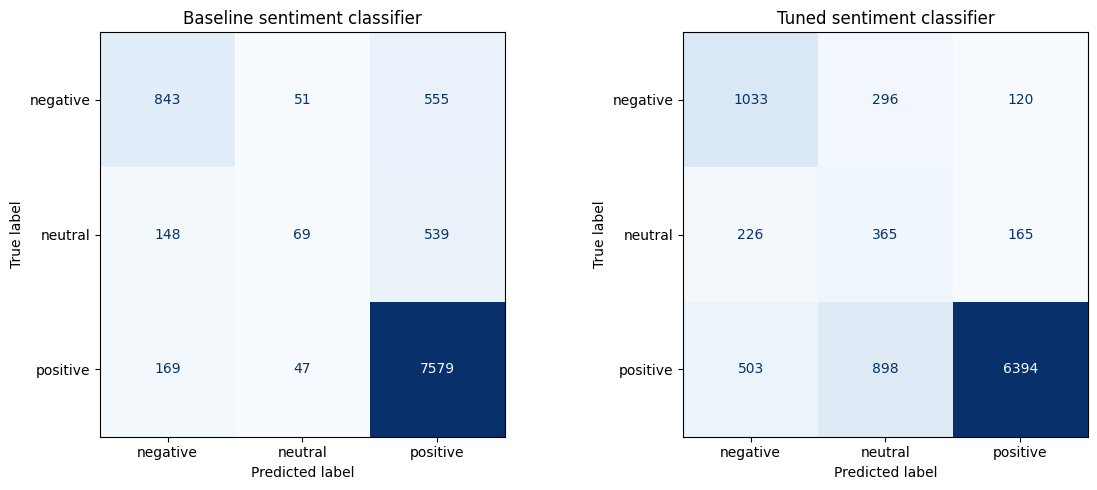

,sentiment,predicted,Text
0,positive,negative,"My dad requested chocolate cake for Father's day and I thought I would try this brand for the first time. I failed to read the box first and make the cake in the steps it called for. It was a little dry, but that wouldn't have happened if I"
1,positive,negative,"I can't count the times I've bought a flavored coffee, opened the bag and inhaled the incredible aroma only to be disappointed that, once brewed the special ""flavor"" either isn't detectable or conversely completely overpowers the coffee its"
2,positive,neutral,"I mean I was really excited to use this. I don't actually wash my hair myself-i'm no good at it. So I took both the shampoo and the <a href=""http://www.amazon.com/gp/product/B007RTR9E2"">CLEAR SCALP & HAIR BEAUTY Ultra Shea Smooth & Nourish"
3,positive,neutral,"Although I have not personally tasted them, Tippy the Pampered Poodle loves them. As a matter of fact, she caught me bringing the bag upstairs to write the review, so she started her performance (spin around dance and jump with a high-five"
4,positive,neutral,"This really is good coffee. It's smooth and goes down easy which is why I'm giving it five stars. However, I was looking for an organic Hazelnut coffee. This isn't it and unfortunately it's difficult to tell from description and reviews. So"
5,positive,neutral,Great coffee with no bitter aftertaste and delicious pumpkin flavor. I used it in an eggnog latte and it was a hit in our house! The only negative is that it doesn't come with a way to reseal the bag i.e. a tin tie or sticker. I used the t


In [11]:
from sklearn.metrics import precision_recall_fscore_support

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(np.zeros((len(y_train), 1)), y_train)
predictions_by_model = {
    'Majority': dummy.predict(np.zeros((len(y_test), 1))),
    'Baseline': baseline.predict(X_test),
    'Tuned': tuned_model.predict(X_test)
}
test_rows = []
class_reports = {}
for name, predictions in predictions_by_model.items():
    test_rows.append({'model': name,
        'accuracy': accuracy_score(y_test, predictions),
        'macro_f1': f1_score(y_test, predictions, average='macro'),
        'weighted_f1': f1_score(y_test, predictions, average='weighted')})
    class_reports[name] = pd.DataFrame(classification_report(
        y_test, predictions, labels=CLASS_ORDER, output_dict=True, zero_division=0)).T
    print('\n', name, 'classification report')
    display(class_reports[name].round(4))
    class_reports[name].to_csv(OUTPUT_DIR / (name.lower() + '_class_report.csv'))
test_results = pd.DataFrame(test_rows).set_index('model')
display(test_results.round(4))
test_results.to_csv(OUTPUT_DIR / 'sentiment_test_results.csv')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name in zip(axes, ['Baseline', 'Tuned']):
    ConfusionMatrixDisplay.from_predictions(y_test, predictions_by_model[name],
        labels=CLASS_ORDER, display_labels=CLASS_ORDER, cmap='Blues',
        colorbar=False, ax=ax)
    ax.grid(False)
    ax.set_title(name + ' sentiment classifier')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'sentiment_confusion_matrices.png', dpi=180)
plt.show()

selected_predictions = predictions_by_model[selected_name]
errors = test_df[['Text', 'sentiment']].copy()
errors['predicted'] = selected_predictions
errors = errors.loc[errors['sentiment'] != errors['predicted']].copy()
errors['Text'] = errors['Text'].str.slice(0, 240)
display(errors[['sentiment', 'predicted', 'Text']].head(6).reset_index(drop=True))
print('Selected-model test errors:', len(errors))

### 3.5 Theme discovery with LDA
Topic modelling is separate from sentiment classification. CountVectorizer supplies non-negative word counts, rather than TF-IDF weights, for six-topic Latent Dirichlet Allocation. The count vocabulary uses at most 5,000 terms, min_df=5 and max_df=0.95. Online LDA runs ten passes with seed 42 on training text.

Each review receives a mixture of six topics. The largest weight is used only to summarise a dominant topic. Six topics is an exploratory choice, not an optimal number established by a search. Keywords and representative reviews support tentative human labels. We inspect class composition within each topic, distinguishing praise from complaints; a topic alone does not encode sentiment. Perplexity or classification accuracy is not presented as proof of business usefulness (scikit-learn developers, n.d.e).

,topic,keywords
0,1,"not, like, taste, good, flavor, just, chocolate, really, sweet, great, love, little"
1,2,"not, food, dog, did, like, product, old, dogs, just, treats, eat, loves"
2,3,"tea, not, drink, like, taste, water, flavor, no, green, cat, sugar, good"
3,4,"use, not, make, product, used, water, chicken, just, easy, no, time, rice"
4,5,"amazon, great, price, product, love, store, good, not, buy, order, box, time"
5,6,"coffee, not, cup, like, flavor, good, taste, cups, beans, great, just, strong"


sentiment,negative,neutral,positive
topic,,,
1,1786,1133,10585
2,1366,479,3876
3,606,417,3639
4,441,258,2728
5,852,349,6695
6,745,386,3659


sentiment,negative,neutral,positive
topic,,,
1,13.23,8.39,78.38
2,23.88,8.37,67.75
3,13.00,8.94,78.06
4,12.87,7.53,79.60
5,10.79,4.42,84.79
6,15.55,8.06,76.39


,topic,sentiment,weight,review_excerpt
0,1,positive,0.988355,"As a gluten intolerant person, I loved it when I found Annie's Macaroni and Cheese, which I always made with lactose-free milk because I'm also lactose intolerant. Found it creamy and yummy and healthier, but otherwise much like those other mac'n'cheese box dinners I ate as a child. For some reason, the cheese in Angie's original gluten-intolerant"
1,1,positive,0.982903,"I feel like I have tried all of the gluten-free chocolate chip cookies on the market, and these are the clear front-runners for me. Njoy Life usually has wonderful stuff, but their chocolate chip cookies don't hold a candle to these. These are also better than Pamela's shortbread chocolate chip cookies and her chocolate chocolate chip cookies. I"
2,2,negative,0.961846,"My Yorkie, didn't really care for these treats. I think they smell and remind her of her dog food.<br />But on the good side the bag does have plenty small treats, good for training. not too big."
3,2,positive,0.957997,"My dog loves these. Problem is if we give him a whole bone or if he eats one close to sleep time...he pukes it up...Not sure why. We ususally just give him a half and he does better with that. He would eat 10 of them if we let him, so he does love these bones."
4,3,negative,0.971126,"I like the concept of these natural, carbonated juice beverages and I really liked the black cherry flavor. But among the three flavors I tried, the Watermelon Strawberry was my least favorite. It has a very syrupy sweet taste. Without a flavor attractive enough to make up for the calories, the carbohydrates and sugar, I'd prefer to stick with wa"
5,3,positive,0.969989,"I love green tea and all it's health benefits. Until I found this brand I was making my green iced tea at home. The blueberry flavor is subtle, but just enough. I love that it's not high calorie but refreshing, and it tastes so good it doesn't need a lot of sweetener."
6,4,positive,0.868959,"Excellent value, with fresh grains, yielding consistent, easy to repeat results. Will make you consider a risotto cookbook if you haven't bought one yet. You may find yourself having risotto in a menu instead of pasta or potato or other grains."
7,4,positive,0.844987,"They should of used this type of bottles for ages. Use to come in tin cans, typically I use it once, and it rots away because there is no good way to store it after opening. Even though this bottle is a bit more costly, but use it, wash it, then buy the tin cans to refill it. Eco friendly and pocket friendly :)"
8,5,positive,0.987540,Great product ... great price .. shipped fast!Great product ... great price .. shipped fast!Great product ... great price .. shipped fast!Great product ... great price .. shipped fast!Great product ... great price .. shipped fast!Great product ... great price .. shipped fast!Great product ... great price .. shipped fast!Great product ... great pric
9,5,positive,0.977816,"These bars are really good! I'm in college where most of the students are commuters, so many students bring their own snacks.<br /><br />One day, one of my girl friends brought this bar to class. They looked yummy, and a few days later I found them at my local grocery store! Love at first bite!!! Perfect for me to bring to work or school! Ever"


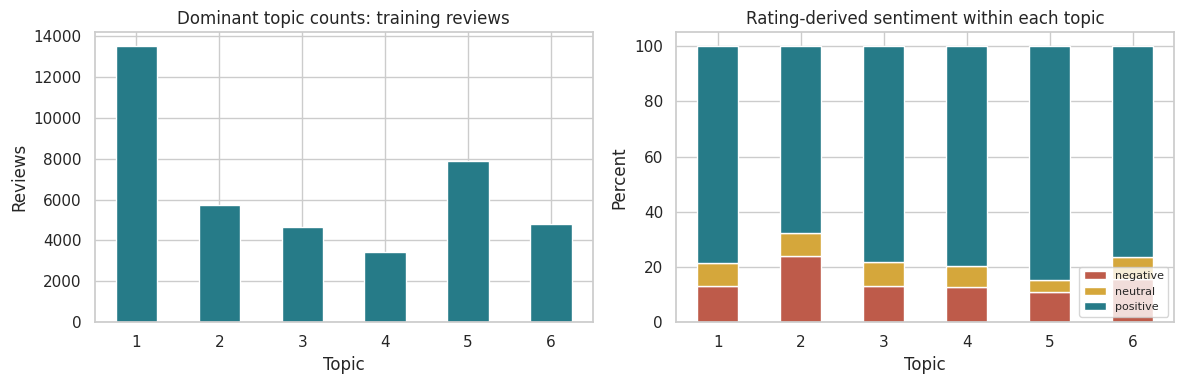

In [12]:
# Fit vocabulary and LDA using training reviews only.
topic_vectorizer = CountVectorizer(max_features=5000, min_df=5, max_df=0.95)
topic_counts = topic_vectorizer.fit_transform(X_train)
lda = LatentDirichletAllocation(n_components=6, max_iter=10,
    learning_method='online', random_state=RANDOM_STATE, n_jobs=1)
topic_weights = lda.fit_transform(topic_counts)
topic_words = topic_vectorizer.get_feature_names_out()

topic_rows = []
for number, weights in enumerate(lda.components_):
    top_indices = weights.argsort()[-12:][::-1]
    topic_rows.append({'topic': number + 1, 'keywords': ', '.join(topic_words[top_indices])})
topic_keywords = pd.DataFrame(topic_rows)
display(topic_keywords)
topic_keywords.to_csv(OUTPUT_DIR / 'topic_keywords.csv', index=False)

topic_df = train_df[['Text', 'sentiment']].copy().reset_index(drop=True)
topic_df['topic'] = topic_weights.argmax(axis=1) + 1
topic_df['dominant_weight'] = topic_weights.max(axis=1)
topic_prevalence = topic_df['topic'].value_counts().sort_index()
topic_composition = pd.crosstab(topic_df['topic'], topic_df['sentiment'])
topic_composition = topic_composition.reindex(columns=CLASS_ORDER, fill_value=0)
topic_percentages = topic_composition.div(topic_composition.sum(axis=1), axis=0) * 100
display(topic_composition)
display(topic_percentages.round(2))
topic_composition.to_csv(OUTPUT_DIR / 'topic_sentiment_counts.csv')
topic_percentages.to_csv(OUTPUT_DIR / 'topic_sentiment_percentages.csv')

# Select highly topic-specific reviews of at least 20 cleaned words for interpretation.
representatives = []
train_word_lengths = X_train.reset_index(drop=True).str.split().str.len()
for number in range(1, 7):
    subset = topic_df.loc[(topic_df['topic'] == number) & (train_word_lengths >= 20)]
    for _, row in subset.nlargest(2, 'dominant_weight').iterrows():
        representatives.append({'topic': number, 'sentiment': row['sentiment'],
            'weight': row['dominant_weight'], 'review_excerpt': row['Text'][:350]})
representative_reviews = pd.DataFrame(representatives)
display(representative_reviews)
representative_reviews.to_csv(OUTPUT_DIR / 'topic_representative_excerpts.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
topic_prevalence.plot.bar(ax=axes[0], color='#267B88', rot=0)
axes[0].set_title('Dominant topic counts: training reviews')
axes[0].set_xlabel('Topic'); axes[0].set_ylabel('Reviews')
topic_percentages.plot.bar(stacked=True, ax=axes[1], rot=0,
    color=['#BE5B4A', '#D5A73B', '#267B88'])
axes[1].set_title('Rating-derived sentiment within each topic')
axes[1].set_ylabel('Percent'); axes[1].set_xlabel('Topic')
axes[1].legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'topic_overview.png', dpi=180)
plt.show()

### 3.6 Historical review patterns
Review timestamps are converted to years in UTC. Training-sample sentiment shares are reported only for years with at least 50 reviews, alongside counts. These are rating-derived historical patterns among retained sampled texts, not a temporal holdout evaluation or a measure of present-day satisfaction. Deduplication can alter time distributions because only the first retained version of repeated text remains.

sentiment,negative,neutral,positive,reviews
year,,,,
2005,12.28,2.63,85.09,114
2006,12.16,6.31,81.53,444
2007,10.64,5.19,84.17,1560
2008,11.28,7.45,81.27,2349
2009,12.21,6.76,81.03,3711
2010,14.40,7.24,78.36,5909
2011,14.92,7.95,77.13,11596
2012,15.85,7.93,76.21,14255


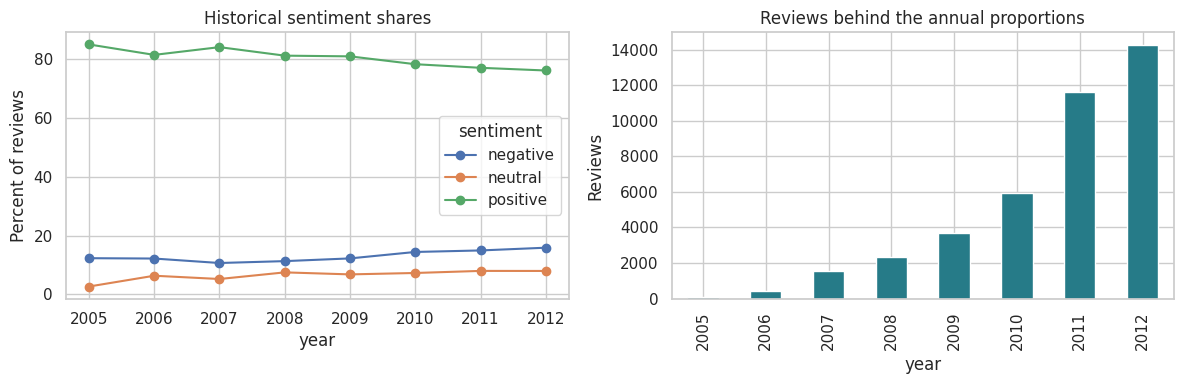

In [13]:
history = train_df[['Time', 'sentiment']].copy()
history['year'] = pd.to_datetime(history['Time'], unit='s', utc=True, errors='coerce').dt.year
annual_counts = pd.crosstab(history['year'], history['sentiment']).reindex(columns=CLASS_ORDER, fill_value=0)
annual_counts = annual_counts.loc[annual_counts.sum(axis=1) >= 50]
annual_shares = annual_counts.div(annual_counts.sum(axis=1), axis=0) * 100
annual_table = annual_shares.copy()
annual_table['reviews'] = annual_counts.sum(axis=1)
display(annual_table.round(2))
annual_table.to_csv(OUTPUT_DIR / 'historical_sentiment.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
annual_shares.plot(ax=axes[0], marker='o')
axes[0].set_ylabel('Percent of reviews'); axes[0].set_title('Historical sentiment shares')
annual_counts.sum(axis=1).plot.bar(ax=axes[1], color='#267B88')
axes[1].set_title('Reviews behind the annual proportions'); axes[1].set_ylabel('Reviews')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'historical_patterns.png', dpi=180)
plt.show()

## Part 4: Interpretation and client findings

### 4.1 Sentiment results and improvement trade-offs
The baseline's mean training-validation macro-F1 is 0.5644 (fold SD 0.0068). The best grid candidate obtains 0.6159 with settings `{'classifier__C': 0.5, 'classifier__class_weight': 'balanced', 'tfidf__ngram_range': [1, 2]}`. **Tuned** is selected using training validation, before consulting test scores.

On 10,000 test reviews, the selected model achieves accuracy 77.92%, macro-F1 0.6141 and weighted-F1 0.8058. Relative to the baseline, macro-F1 changes by +0.0420 and accuracy by -6.99 percentage points. This is an observed comparison, not a guarantee that tuning improves every metric.

Neutral recall is 48.28%, compared with 71.29% for negative and 82.03% for positive. Three-star reviews are a broad rating-based proxy: mixed wording, subtle language and label noise can make them difficult to distinguish. That explanation is a hypothesis supported by error inspection, not a measured causal result. Classification metrics follow scikit-learn developers (n.d.d).

### 4.2 Exploratory theme labels
Topic labels below are tentative human descriptions based on keywords and representative reviews, not ground-truth topic annotations. Counts use the highest-weight topic for each training review; reviews can contain several themes. Percentages are rating-derived, not predictions from the sentiment model.

| Topic | Tentative label | Training reviews | Negative share | Interpretation |
|---|---|---:|---:|---|
| 1 | Taste and food preferences | 13,504 | 13.23% | Broad flavour and sweetness discussion; representative texts include dietary-preference foods. This is a mixed theme. |
| 2 | Pet food and treat acceptance | 5,721 | 23.88% | Dog food and treats feature prominently. This topic has the highest negative share, but ratings and review wording can disagree. |
| 3 | Tea and other drinks | 4,662 | 13.00% | Tea, water, sweetness and drink flavour occur together; the cat keyword indicates imperfect separation. |
| 4 | Preparation and product use | 3,427 | 12.87% | Rice, cooking and practical use appear, with some packaging/storage discussion in examples. |
| 5 | Purchasing and value | 7,896 | 10.79% | Price, ordering and shopping context appear. This topic has the largest positive share, not proof that every transaction went well. |
| 6 | Coffee flavour and preparation | 4,790 | 15.55% | Coffee, cups, beans and strength are coherent keywords; some very high-weight excerpts are repetitive and uninformative. |

The representative excerpts are available above. Keyword overlap and generic words limit distinctiveness. Some highest-weight excerpts are repetitive and are not treated as substantive evidence for a topic label. No claim is made that six topics is optimal or that the topics cover every business issue. Inspect a broader random set of reviews within each topic and sentiment before making product-specific decisions.

### 4.3 Business recommendations
**Taste and food preferences:** Review taste and sweetness complaints by product before changing recipes; preserve flavour characteristics that customers praise.

**Pet food and treat acceptance:** Prioritise a product-level review of pet-food and treat acceptance complaints; check the volume and wording before drawing conclusions.

**Tea and other drinks:** Check drink flavour and sweetness descriptions against negative feedback; inspect mixed-topic reviews manually.

**Preparation and product use:** Check preparation and storage instructions and packaging usability against additional reviews before changing product guidance.

**Purchasing and value:** Preserve well-received value offers and investigate ordering complaints separately; verify issues against transaction evidence.

**Coffee flavour and preparation:** Review coffee flavour and strength feedback by product and preparation method; manually screen repetitive text before using it as evidence.

Prioritise human investigation using both negative share and the number of negative reviews. These are review-pattern signals, not established causes or estimates of commercial loss. Preserve commonly praised features while investigating dissatisfaction. Monitor new reviews using manually validated labels before deploying alerts.

### 4.4 Limitations and conclusion
Ratings are imperfect sentiment proxies. Deduplication and removing conflicting labels change the target population and can discard genuine repeated feedback. Conflict detection uses the supplied corpus before splitting, so evaluation is conditional on that data-selection rule. Exact clean-text overlap is prevented, but near duplicates and shared products or reviewers can still cross a random split; grouped or chronological evaluation is future work.

The 50,000-review sample is stratified by sentiment, not guaranteed representative by product or year. Historical patterns are not current customer satisfaction. Stopword removal can alter phrase context, and no lemmatisation is performed. Vocabulary limits may omit useful rare terms. Grid-search validation is non-nested; winning validation scores have selection optimism. LDA uses a single six-topic configuration, with no stability/coherence search or external topic annotations. Quantitative classification metrics cannot validate unlabelled topic quality.

The notebook completes two complementary tasks: supervised rating-derived sentiment classification and unsupervised theme discovery. Its findings support targeted manual review and further validation rather than automated assumptions about individual customers.

## References
scikit-learn developers (n.d.a). *Common pitfalls and recommended practices.* Available at: https://scikit-learn.org/stable/common_pitfalls.html (Accessed: 21 October 2026).

scikit-learn developers (n.d.b). *Feature extraction.* Available at: https://scikit-learn.org/stable/modules/feature_extraction.html (Accessed: 21 October 2026).

scikit-learn developers (n.d.c). *GridSearchCV.* Available at: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html (Accessed: 21 October 2026).

scikit-learn developers (n.d.d). *Metrics and scoring: quantifying the quality of predictions.* Available at: https://scikit-learn.org/stable/modules/model_evaluation.html (Accessed: 21 October 2026).

scikit-learn developers (n.d.e). *LatentDirichletAllocation.* Available at: https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.LatentDirichletAllocation.html (Accessed: 21 October 2026).

SNAP (n.d.). *Amazon Fine Food Reviews [CSV dataset distributed on Kaggle].* Available at: https://www.kaggle.com/datasets/snap/amazon-fine-food-reviews (Accessed: 21 October 2026).

Stanford Network Analysis Project (n.d.). *Web data: Amazon Fine Foods reviews.* Available at: https://snap.stanford.edu/data/web-FineFoods.html (Accessed: 21 October 2026).